#  Sleep Stage Classification using Temporal Convolutional Networks (TCN)


---

## Step 1: Install Dependencies

In [ ]:
# Install required libraries
!pip install mne pyedflib -q
!pip install torch torchvision torchaudio -q
!pip install scikit-learn matplotlib seaborn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 38.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.2.1 which is incompatible.


## Step 2: Import Libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import mne
from mne.datasets.sleep_physionet.age import fetch_data

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: cuda


## Step 3: Download Dataset



In [ ]:
# Download recordings for subjects 0 and 1 (2 subjects = 4 recordings)
# Each subject has a 'night1' and 'night2' recording
SUBJECTS = [0, 1]
RECORDINGS = [1, 2]
print('Downloading Sleep-EDF data from PhysioNet...')
files = fetch_data(subjects=SUBJECTS, recording=RECORDINGS)
print(f'Downloaded {len(files)} file pairs.')
for pair in files:
    print(' -', pair)

Using default location ~/mne_data for PHYSIONET_SLEEP...
Creating /root/mne_data


  0%|                                              | 0.00/48.3M [00:00<?, ?B/s]

  0%|                                              | 0.00/4.62k [00:00<?, ?B/s]

  0%|                                              | 0.00/51.6M [00:00<?, ?B/s]

  0%|                                              | 0.00/4.58k [00:00<?, ?B/s]

  0%|                                              | 0.00/51.1M [00:00<?, ?B/s]

  0%|                                              | 0.00/3.90k [00:00<?, ?B/s]

  0%|                                              | 0.00/52.0M [00:00<?, ?B/s]

  0%|                                              | 0.00/5.08k [00:00<?, ?B/s]

Download complete in 17m48s (193.7 MB)
Downloaded 4 file pairs.
 - ['/root/mne_data/physionet-sleep-data/SC4001E0-PSG.edf', '/root/mne_data/physionet-sleep-data/SC4001EC-Hypnogram.edf']
 - ['/root/mne_data/physionet-sleep-data/SC4002E0-PSG.edf', '/root/mne_data/physionet-sleep-data/SC4002EC-Hypnogram.edf']
 - ['/root/mne_data/physionet-sleep-data/SC4011E0-PSG.edf', '/root/mne_data/physionet-sleep-data/SC4011EH-Hypnogram.edf']
 - ['/root/mne_data/physionet-sleep-data/SC4012E0-PSG.edf', '/root/mne_data/physionet-sleep-data/SC4012EC-Hypnogram.edf']


## Step 4: Data Loading and Epoch Extraction



In [ ]:
# Sleep stage label mapping — MNE uses string annotations
STAGE_MAP = {
    'Sleep stage W':  0,  # Wake
    'Sleep stage 1':  1,  # N1
    'Sleep stage 2':  2,  # N2
    'Sleep stage 3':  3,  # N3
    'Sleep stage 4':  3,  # N3
    'Sleep stage R':  4,  # REM
}
STAGE_NAMES = ['Wake', 'N1', 'N2', 'N3', 'REM']

EEG_CHANNEL  = 'EEG Fpz-Cz'
EPOCH_SEC    = 30
TMIN, TMAX   = -0.5, EPOCH_SEC - 0.5


def load_subject_epochs(psg_file, hyp_file):
    """
    Load a single subject's PSG + hypnogram,
    extract 30-s epochs from Fpz-Cz, and return
    (epochs_array [N, T], labels [N]).
    """
    #Load raw EEG
    raw = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
    sfreq = raw.info['sfreq']
    n_samples = int(EPOCH_SEC * sfreq)

    # Pick only the Fpz-Cz channel
    if EEG_CHANNEL not in raw.ch_names:
        # Try alternate naming
        ch = [c for c in raw.ch_names if 'Fpz' in c or 'EEG' in c]
        if not ch:
            raise ValueError(f'Channel {EEG_CHANNEL} not found in {psg_file}')
        raw.pick_channels([ch[0]])
    else:
        raw.pick_channels([EEG_CHANNEL])

    #Load annotations (hypnogram)
    annot = mne.read_annotations(hyp_file)
    raw.set_annotations(annot, emit_warning=False)

    # Build events from annotations
    events, event_id = mne.events_from_annotations(
        raw, event_id=STAGE_MAP, chunk_duration=EPOCH_SEC, verbose=False
    )

    if len(events) == 0:
        return np.array([]), np.array([])

    # Extract fixed-length epochs
    epochs = mne.Epochs(
        raw, events, tmin=0, tmax=EPOCH_SEC - 1/sfreq,
        baseline=None, preload=True,
        on_missing='ignore', verbose=False
    )

    data   = epochs.get_data()[:, 0, :]
    labels = epochs.events[:, 2]

    return data, labels
# Collect all epochs
all_data, all_labels = [], []

for psg_file, hyp_file in files:
    try:
        data, labels = load_subject_epochs(psg_file, hyp_file)
        if len(data) > 0:
            all_data.append(data)
            all_labels.append(labels)
            print(f'Loaded {len(data)} epochs from {os.path.basename(psg_file)}')
    except Exception as e:
        print(f'Warning: Could not load {psg_file}: {e}')

X = np.concatenate(all_data,   axis=0)
y = np.concatenate(all_labels, axis=0)

print(f'\nTotal epochs: {X.shape[0]}')
print(f'Samples per epoch: {X.shape[1]}')
print(f'Label distribution:')
unique, counts = np.unique(y, return_counts=True)
for u, c in zip(unique, counts):
    print(f'  {STAGE_NAMES[u]:6s} (class {u}): {c} epochs')

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Loaded 2650 epochs from SC4001E0-PSG.edf
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Loaded 2829 epochs from SC4002E0-PSG.edf
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Loaded 2802 epochs from SC4011E0-PSG.edf
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Loaded 2848 epochs from SC4012E0-PSG.edf

Total epochs: 11129
Samples per epoch: 3000
Label distribution:
  Wake   (class 0): 7562 epochs
  N1     (class 1): 318 epochs
  N2     (class 2): 1845 epochs
  N3     (class 3): 718 epochs
  REM    (class 4): 686 epochs


## Step 5: Preprocessing



In [ ]:
#1. Remove invalid (NaN / Inf / flat) epochs
def is_valid(epoch):
    if np.any(np.isnan(epoch)) or np.any(np.isinf(epoch)):
        return False
    if np.std(epoch) < 1e-6:
        return False
    amplitude = np.max(np.abs(epoch))
    if amplitude > 0.001:
        return False
    return True

valid_mask = np.array([is_valid(epoch) for epoch in X])
X_clean = X[valid_mask]
y_clean = y[valid_mask]
print(f'Removed {np.sum(~valid_mask)} invalid epochs. Remaining: {len(X_clean)}')

# 2. Per-epoch standardization (zero mean, unit std)
mean = X_clean.mean(axis=1, keepdims=True)
std  = X_clean.std(axis=1,  keepdims=True) + 1e-8
X_norm = (X_clean - mean) / std

# 3. Reshape to (N, 1, T) for Conv1D
X_norm = X_norm[:, np.newaxis, :]

# 4. Train / Val / Test split
X_tv, X_test, y_tv, y_test = train_test_split(
    X_norm, y_clean, test_size=0.15, random_state=SEED, stratify=y_clean
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=0.176, random_state=SEED, stratify=y_tv
)
print(f'Train : {len(X_train)} | Val : {len(X_val)} | Test : {len(X_test)}')

# 5. Convert to tensors
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.LongTensor(y_train)
X_val_t   = torch.FloatTensor(X_val)
y_val_t   = torch.LongTensor(y_val)
X_test_t  = torch.FloatTensor(X_test)
y_test_t  = torch.LongTensor(y_test)

Removed 0 invalid epochs. Remaining: 11129
Train : 7794 | Val : 1665 | Test : 1670


## Step 6: Dataset & DataLoader

In [ ]:
class EEGDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# Weighted sampler to handle class imbalance
def make_weighted_sampler(labels):
    class_counts = np.bincount(labels)
    class_weights = 1.0 / (class_counts + 1e-8)
    sample_weights = class_weights[labels]
    return WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )

BATCH_SIZE = 64

train_dataset = EEGDataset(X_train_t, y_train_t)
val_dataset   = EEGDataset(X_val_t,   y_val_t)
test_dataset  = EEGDataset(X_test_t,  y_test_t)

train_sampler = make_weighted_sampler(y_train)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f'Train batches: {len(train_loader)}')
print(f'Val   batches: {len(val_loader)}')
print(f'Test  batches: {len(test_loader)}')

Train batches: 122
Val   batches: 27
Test  batches: 27


## Step 7: TCN Model Architecture



In [ ]:
class CausalConv1d(nn.Module):
    """
    1D Convolution with causal (left-only) padding and dilation.
    Output at time t depends only on inputs at times <= t.
    Weight normalization is applied directly to the inner Conv1d.
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation=1):
        super().__init__()
        # Causal padding: pad only the left side
        self.padding = (kernel_size - 1) * dilation
        # Apply weight_norm directly on the Conv1d (it HAS a 'weight' attribute)
        self.conv = nn.utils.weight_norm(
            nn.Conv1d(
                in_channels, out_channels,
                kernel_size=kernel_size,
                padding=0,
                dilation=dilation
            )
        )
        nn.init.kaiming_normal_(self.conv.weight_v)

    def forward(self, x):
        # Pad only the left (past) side → causal
        x = F.pad(x, (self.padding, 0))
        return self.conv(x)


class TemporalBlock(nn.Module):
    """
    One TCN residual block with two causal dilated convolutions.
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout=0.2):
        super().__init__()

        self.conv1 = CausalConv1d(in_channels,  out_channels, kernel_size, dilation)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout)

        self.conv2 = CausalConv1d(out_channels, out_channels, kernel_size, dilation)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout)

        # 1×1 conv for residual when channel dims differ
        self.residual_conv = (
            nn.Conv1d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels else None
        )
        self.relu_out = nn.ReLU()

    def forward(self, x):
        out = self.drop1(self.relu1(self.conv1(x)))
        out = self.drop2(self.relu2(self.conv2(out)))
        res = x if self.residual_conv is None else self.residual_conv(x)
        return self.relu_out(out + res)


class TCN(nn.Module):
    """
    Temporal Convolutional Network for EEG sleep stage classification.

    Architecture:
      - Input: (batch, 1, T)  — single EEG channel
      - N stacked TemporalBlocks with exponentially increasing dilation
      - Global average pooling over the time axis
      - Fully-connected classifier head
    """
    def __init__(
        self,
        in_channels=1,
        num_classes=5,
        num_channels=[64, 64, 128, 128],  # Channels per block
        kernel_size=3,
        dropout=0.2
    ):
        super().__init__()
        layers = []
        n_blocks = len(num_channels)
        for i, out_ch in enumerate(num_channels):
            in_ch   = in_channels if i == 0 else num_channels[i - 1]
            dilation = 2 ** i       # 1, 2, 4, 8 ...
            layers.append(
                TemporalBlock(in_ch, out_ch, kernel_size, dilation, dropout)
            )
        self.tcn = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Linear(num_channels[-1], 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x: (B, 1, T)
        out = self.tcn(x)               # (B, C, T)
        out = out.mean(dim=2)           # Global average pooling → (B, C)
        return self.classifier(out)     # (B, num_classes)


# Instantiate model
model = TCN(
    in_channels=1,
    num_classes=5,
    num_channels=[64, 64, 128, 128],
    kernel_size=3,
    dropout=0.2
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'\nTrainable parameters: {total_params:,}')

TCN(
  (tcn): Sequential(
    (0): TemporalBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(1, 64, kernel_size=(3,), stride=(1,))
      )
      (relu1): ReLU()
      (drop1): Dropout(p=0.2, inplace=False)
      (conv2): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(3,), stride=(1,))
      )
      (relu2): ReLU()
      (drop2): Dropout(p=0.2, inplace=False)
      (residual_conv): Conv1d(1, 64, kernel_size=(1,), stride=(1,))
      (relu_out): ReLU()
    )
    (1): TemporalBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(3,), stride=(1,), dilation=(2,))
      )
      (relu1): ReLU()
      (drop1): Dropout(p=0.2, inplace=False)
      (conv2): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(3,), stride=(1,), dilation=(2,))
      )
      (relu2): ReLU()
      (drop2): Dropout(p=0.2, inplace=False)
      (relu_out): ReLU()
    )
    (2): TemporalBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(64, 128, kernel_size=(3,), 

## Step 8: Loss Function, Optimizer, and Scheduler

In [ ]:
# Compute class weights to handle imbalance in loss function
class_counts = np.bincount(y_train, minlength=5)
class_weights = 1.0 / (class_counts + 1e-8)
class_weights = class_weights / class_weights.sum() * 5   # Normalize
class_weights_tensor = torch.FloatTensor(class_weights).to(DEVICE)

print('Class weights for loss function:')
for i, (name, w) in enumerate(zip(STAGE_NAMES, class_weights)):
    print(f'  {name}: {w:.4f}  (count: {class_counts[i]})')

# Cross-entropy loss with class weights
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# AdamW optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Cosine annealing LR scheduler
NUM_EPOCHS = 50
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

Class weights for loss function:
  Wake: 0.0992  (count: 5296)
  N1: 2.3556  (count: 223)
  N2: 0.4066  (count: 1292)
  N3: 1.0443  (count: 503)
  REM: 1.0944  (count: 480)


## Step 9: Training Loop

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(y_batch)
        preds       = logits.argmax(dim=1)
        correct    += (preds == y_batch).sum().item()
        total      += len(y_batch)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_targets = [], []

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)

        total_loss += loss.item() * len(y_batch)
        preds       = logits.argmax(dim=1)
        correct    += (preds == y_batch).sum().item()
        total      += len(y_batch)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())

    return total_loss / total, correct / total, np.array(all_preds), np.array(all_targets)


# -------- Training --------
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
PATIENCE = 10
patience_counter = 0

for epoch in range(1, NUM_EPOCHS + 1):
    t_loss, t_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    v_loss, v_acc, _, _ = evaluate(model, val_loader, criterion)
    scheduler.step()

    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_acc'].append(t_acc)
    history['val_acc'].append(v_acc)

    # Save best model
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        torch.save(model.state_dict(), 'best_tcn.pth')
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:3d}/{NUM_EPOCHS}  '
              f'Train Loss: {t_loss:.4f}  Train Acc: {t_acc:.4f}  '
              f'Val Loss: {v_loss:.4f}  Val Acc: {v_acc:.4f}')

    # Early stopping
    if patience_counter >= PATIENCE:
        print(f'Early stopping at epoch {epoch}')
        break

print(f'\nBest validation loss: {best_val_loss:.4f}')

Epoch   1/50  Train Loss: 1.3173  Train Acc: 0.2071  Val Loss: 2.1271  Val Acc: 0.0288
Epoch   5/50  Train Loss: 0.7598  Train Acc: 0.4687  Val Loss: 1.4928  Val Acc: 0.1514
Epoch  10/50  Train Loss: 0.6283  Train Acc: 0.5771  Val Loss: 0.9280  Val Acc: 0.4787
Epoch  15/50  Train Loss: 0.5225  Train Acc: 0.7212  Val Loss: 0.8680  Val Acc: 0.6631
Epoch  20/50  Train Loss: 0.4694  Train Acc: 0.7615  Val Loss: 0.6892  Val Acc: 0.7610
Epoch  25/50  Train Loss: 0.4208  Train Acc: 0.8016  Val Loss: 0.5582  Val Acc: 0.8186
Epoch  30/50  Train Loss: 0.3941  Train Acc: 0.8134  Val Loss: 0.5775  Val Acc: 0.7976
Epoch  35/50  Train Loss: 0.3796  Train Acc: 0.8191  Val Loss: 0.5276  Val Acc: 0.8186
Epoch  40/50  Train Loss: 0.3403  Train Acc: 0.8360  Val Loss: 0.5270  Val Acc: 0.8246
Early stopping at epoch 44

Best validation loss: 0.4894


## Step 10: Training & Validation Loss/Accuracy Curves

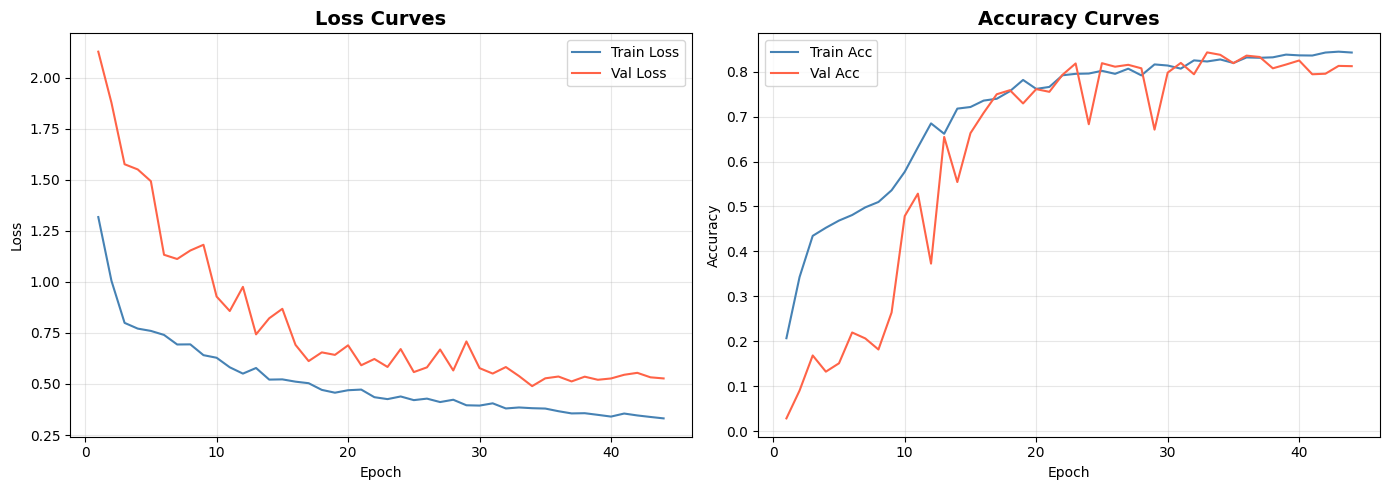

Saved: training_curves.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_ran = range(1, len(history['train_loss']) + 1)

# Loss
axes[0].plot(epochs_ran, history['train_loss'], label='Train Loss', color='steelblue')
axes[0].plot(epochs_ran, history['val_loss'],   label='Val Loss',   color='tomato')
axes[0].set_title('Loss Curves', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(epochs_ran, history['train_acc'], label='Train Acc', color='steelblue')
axes[1].plot(epochs_ran, history['val_acc'],   label='Val Acc',   color='tomato')
axes[1].set_title('Accuracy Curves', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: training_curves.png')

## Step 11: Evaluation on Test Set

In [ ]:
# Load best model checkpoint
model.load_state_dict(torch.load('best_tcn.pth', map_location=DEVICE))

test_loss, test_acc, y_pred, y_true = evaluate(model, test_loader, criterion)

# Compute metrics
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
recall    = recall_score(y_true, y_pred,    average='macro', zero_division=0)
f1        = f1_score(y_true, y_pred,        average='macro', zero_division=0)

print('=' * 50)
print('         TEST SET EVALUATION RESULTS')
print('=' * 50)
print(f'Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)')
print(f'Precision : {precision:.4f}  (macro)')
print(f'Recall    : {recall:.4f}  (macro)')
print(f'F1-Score  : {f1:.4f}  (macro)')
print('=' * 50)
print()
print('Per-class report:')
print(classification_report(
    y_true, y_pred,
    target_names=STAGE_NAMES,
    zero_division=0
))

         TEST SET EVALUATION RESULTS
Accuracy  : 0.8395  (83.95%)
Precision : 0.7006  (macro)
Recall    : 0.8427  (macro)
F1-Score  : 0.7138  (macro)

Per-class report:
              precision    recall  f1-score   support

        Wake       1.00      0.87      0.93      1135
          N1       0.20      0.87      0.33        47
          N2       0.99      0.68      0.81       277
          N3       0.64      0.99      0.78       108
         REM       0.67      0.81      0.73       103

    accuracy                           0.84      1670
   macro avg       0.70      0.84      0.71      1670
weighted avg       0.93      0.84      0.87      1670



## Step 12: Confusion Matrix

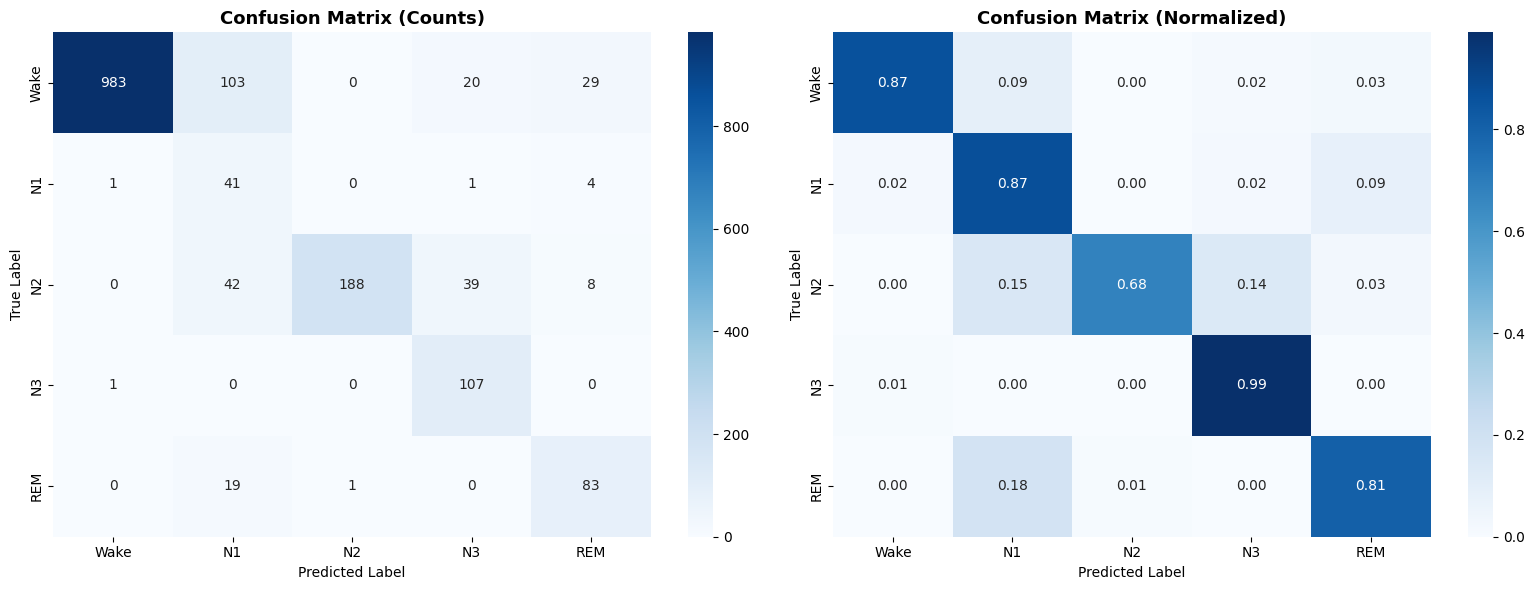

Saved: confusion_matrix.png


In [ ]:
cm = confusion_matrix(y_true, y_pred)

# Normalize per true class
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=STAGE_NAMES, yticklabels=STAGE_NAMES, ax=axes[0]
)
axes[0].set_title('Confusion Matrix (Counts)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label'); axes[0].set_ylabel('True Label')

# Normalized
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=STAGE_NAMES, yticklabels=STAGE_NAMES, ax=axes[1]
)
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Label'); axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion_matrix.png')

## Step 13: Per-Class Performance Bar Chart

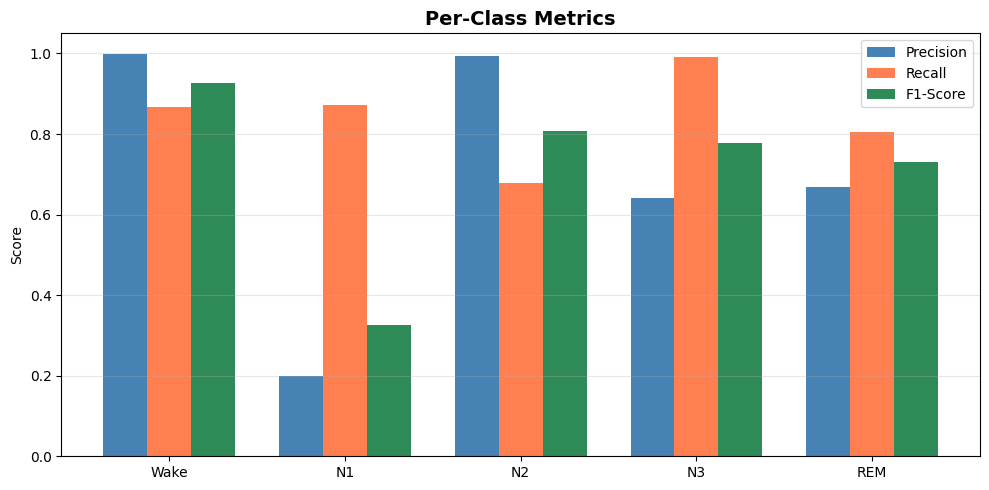

Saved: per_class_metrics.png


In [ ]:
from sklearn.metrics import precision_recall_fscore_support

p, r, f, _ = precision_recall_fscore_support(
    y_true, y_pred, average=None, zero_division=0, labels=list(range(5))
)

x = np.arange(len(STAGE_NAMES))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, p, width, label='Precision', color='steelblue')
ax.bar(x,         r, width, label='Recall',    color='coral')
ax.bar(x + width, f, width, label='F1-Score',  color='seagreen')

ax.set_xticks(x); ax.set_xticklabels(STAGE_NAMES)
ax.set_ylim(0, 1.05)
ax.set_title('Per-Class Metrics', fontsize=14, fontweight='bold')
ax.set_ylabel('Score'); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: per_class_metrics.png')

## Step 14: Class Distribution Visualization

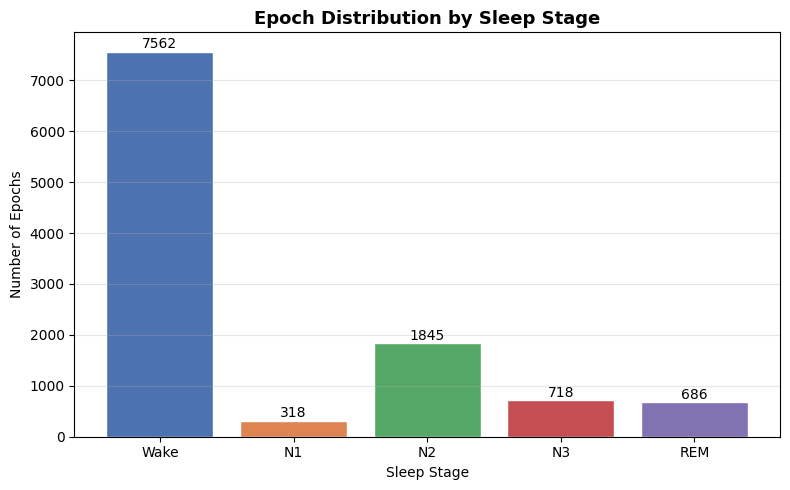

In [ ]:
unique, counts = np.unique(y_clean, return_counts=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2']
bars = ax.bar(
    [STAGE_NAMES[u] for u in unique], counts,
    color=[colors[u] for u in unique], edgecolor='white'
)
for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5, str(count),
        ha='center', va='bottom', fontsize=10
    )
ax.set_title('Epoch Distribution by Sleep Stage', fontsize=13, fontweight='bold')
ax.set_xlabel('Sleep Stage'); ax.set_ylabel('Number of Epochs')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 15: Summary

In [ ]:
print('╔══════════════════════════════════════════════════╗')
print('║       SLEEP STAGE CLASSIFICATION — SUMMARY      ║')
print('╠══════════════════════════════════════════════════╣')
print(f'║  Model        : TCN (4 Temporal Blocks)          ║')
print(f'║  Parameters   : {total_params:,}                    ║'[:51] + '║')
print(f'║  EEG Channel  : Fpz-Cz (single channel)          ║')
print(f'║  Epoch Length : 30 seconds                       ║')
print(f'║  Total Epochs : {len(X_clean):,}                          ║'[:51] + '║')
print('╠══════════════════════════════════════════════════╣')
print(f'║  Test Accuracy  : {accuracy*100:6.2f}%                      ║'[:51] + '║')
print(f'║  Test Precision : {precision:.4f} (macro)                ║'[:51] + '║')
print(f'║  Test Recall    : {recall:.4f} (macro)                ║'[:51] + '║')
print(f'║  Test F1-Score  : {f1:.4f} (macro)                ║'[:51] + '║')
print('╚══════════════════════════════════════════════════╝')

╔══════════════════════════════════════════════════╗
║       SLEEP STAGE CLASSIFICATION — SUMMARY      ║
╠══════════════════════════════════════════════════╣
║  Model        : TCN (4 Temporal Blocks)          ║
║  Parameters   : 227,653                    ║║
║  EEG Channel  : Fpz-Cz (single channel)          ║
║  Epoch Length : 30 seconds                       ║
║  Total Epochs : 11,129                          ║║
╠══════════════════════════════════════════════════╣
║  Test Accuracy  :  83.95%                      ║║
║  Test Precision : 0.7006 (macro)                ║║
║  Test Recall    : 0.8427 (macro)                ║║
║  Test F1-Score  : 0.7138 (macro)                ║║
╚══════════════════════════════════════════════════╝
